In [1]:
import math
import matplotlib.pyplot as plt

E_lab = 830.0      # resonance energy, keV
w_direct = 100.0   # neutron strength, direct
w_indirect = 42.0  # neutron strength, indirect
w_gamma = 35.0     # gamma strength


In [2]:
E_cm = E_lab * 22 / 26
E_cm_MeV = E_cm / 1000
mu = 22 * 4 / 26
print("E_cm =", E_cm, "keV")
print("mu =", mu)


E_cm = 702.3076923076923 keV
mu = 3.3846153846153846


In [3]:
T_list = []
d_list = []
d_up = []
d_down = []
i_list = []
g_list = []

for i in range(15, 101):
    T9 = i / 100
    a = mu * T9
    a_power = a * math.sqrt(a)
    part1 = 1.5394e11 / a_power
    part2 = math.exp(-11.605 * E_cm_MeV / T9)
    r100 = part1 * 100 * 1e-12 * part2
    T_list.append(T9)
    d_list.append(r100)
    d_up.append(r100 * 122 / 100)
    d_down.append(r100 * 78 / 100)
    i_list.append(r100 * 42 / 100)
    g_list.append(r100 * 35 / 100)

print("points made:", len(T_list))


points made: 86


In [4]:
for T9 in [0.2, 0.3, 0.5, 1.0]:
    a = mu * T9
    a_power = a * math.sqrt(a)
    part1 = 1.5394e11 / a_power
    part2 = math.exp(-11.605 * E_cm_MeV / T9)
    r = part1 * 100 * 1e-12 * part2
    print(T9, r, r * 42 / 100, r * 35 / 100)


0.2 5.539016798550413e-17 2.3263870553911732e-17 1.9386558794926448e-17
0.3 2.3914743862386724e-11 1.0044192422202424e-11 8.370160351835354e-12
0.5 5.826242560226799e-07 2.4470218752952557e-07 2.0391848960793798e-07
1.0 0.0007136175661186908 0.00029971937776985017 0.0002497661481415418


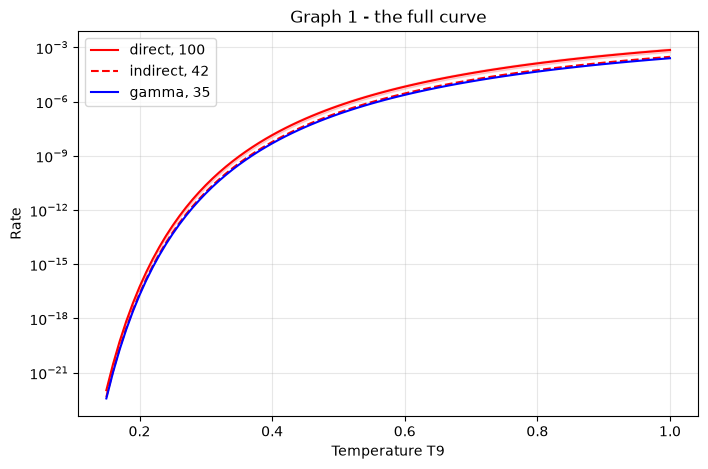

In [5]:
plt.figure(figsize=(8, 5))
plt.fill_between(T_list, d_down, d_up, color="red", alpha=0.15)
plt.plot(T_list, d_list, color="red", label="direct, 100")
plt.plot(T_list, i_list, color="red", linestyle="--", label="indirect, 42")
plt.plot(T_list, g_list, color="blue", label="gamma, 35")
plt.yscale("log")
plt.xlabel("Temperature T9")
plt.ylabel("Rate")
plt.title("Graph 1 - the full curve")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()


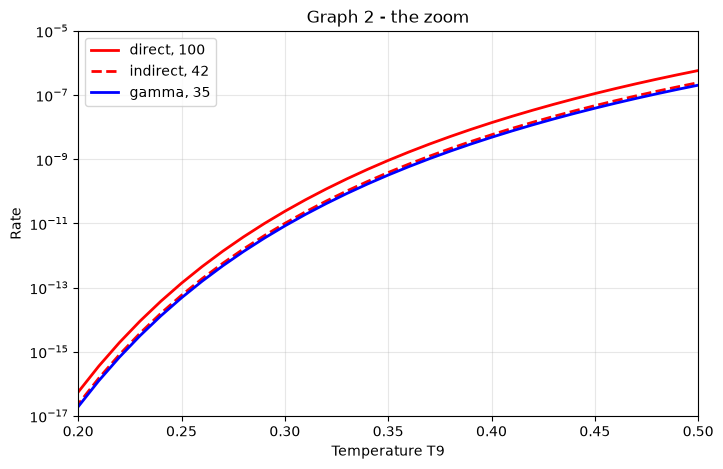

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(T_list, d_list, color="red", linewidth=2, label="direct, 100")
plt.plot(T_list, i_list, color="red", linestyle="--", linewidth=2, label="indirect, 42")
plt.plot(T_list, g_list, color="blue", linewidth=2, label="gamma, 35")
plt.yscale("log")
plt.xlim(0.2, 0.5)
plt.ylim(1e-17, 1e-5)
plt.xlabel("Temperature T9")
plt.ylabel("Rate")
plt.title("Graph 2 - the zoom")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()


direct ratio   = 2.857142857142857 +/- 0.7083249830052265
indirect ratio = 1.2 +/- 0.34290475859834285


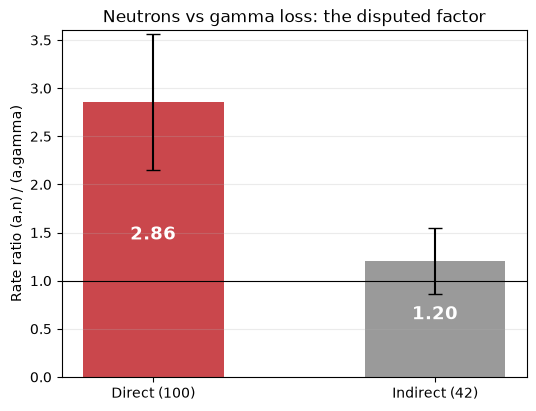

In [7]:
ratio_direct = w_direct / w_gamma      # 2.86
ratio_indirect = w_indirect / w_gamma  # 1.20

# errors of the ratios (small errors, square, add, square root)
e2 = 4 / 35
e1 = 22 / 100
err_direct = ratio_direct * math.sqrt(e1 * e1 + e2 * e2)      # 0.71
e3 = 11 / 42
err_indirect = ratio_indirect * math.sqrt(e3 * e3 + e2 * e2)  # 0.34
print("direct ratio   =", ratio_direct, "+/-", err_direct)
print("indirect ratio =", ratio_indirect, "+/-", err_indirect)

names = ["Direct (100)", "Indirect (42)"]
values = [ratio_direct, ratio_indirect]
errors = [err_direct, err_indirect]

plt.figure(figsize=(6, 4.5))
plt.bar(names, values, yerr=errors, capsize=5, width=0.5,
        color=["#c1272d", "#888888"], alpha=0.85)
plt.axhline(1.0, color="black", linewidth=0.8)
plt.text(0, ratio_direct / 2, "2.86", ha="center", fontsize=13,
         color="white", fontweight="bold")
plt.text(1, ratio_indirect / 2, "1.20", ha="center", fontsize=13,
         color="white", fontweight="bold")
plt.ylabel("Rate ratio (a,n) / (a,gamma)")
plt.title("Neutrons vs gamma loss: the disputed factor")
plt.ylim(0, 3.6)
plt.grid(True, axis="y", alpha=0.25)
plt.show()
